# E89: Does VPD's adversary fail doing nothing on a larger update?

**The answer.** On an update about ten times the first fine-tune's size, VPD's adversary fails doing nothing, which it passed at the smaller size. It also fails the rarely-on half with its remainder in Δ. Both fails compute and the independent check found no bug. But no saved number shows whether do-nothing's fail is damage under masks or the adversary switching part of the update off. The updates also differ in kind, and no good state was read, so nothing shows the test separates good placements from bad.

*Provisional. Independent check: holds with a caveat, `reports/reviews/2026-11-05_review_e89-independent-check.md`. D1 is a map on Qwen3-1.7B that keeps the decomposition faithful for a real update, judged by a test that can fail a bad placement.*


## What we were trying to test

D1 needs a test that can fail a bad placement. On the first fine-tune update, VPD's adversary passed doing nothing, so nobody knew whether it could see an update left in Δ. This run asks whether doing nothing fails on a real update about ten times larger.

**The update.** It is the TOFU fine-tune from the run labelled E81, on invented author biographies, one wording of each fact, 9.6 times the first update by norm. The user chose a different update as the second anchor, from the run labelled E84, trained on five wordings. Their sizes are about the same, but kind and training differ. So nothing here reads the chosen anchor. u1 below is ten maths steps saved in bf16, and this update 1,250 biography steps saved in fp32.

**Terms.**

- **W0 and u1.** W0 is Qwen3-1.7B before any update. u1 is the first update, ten fine-tune steps on maths problems.
- **Subcomponents and Δ.** Each weight matrix is rank-one subcomponents plus a leftover Δ. Γ gives each subcomponent a causal importance $g$ from 0 to 1 per token. Γ never moves here.
- **The adversary.** It sets each subcomponent's strength to $m = g + (1-g)s$ with $s$ from 0 to 1, shared by all rows, and picks how much of Δ to keep. It takes 20 sign steps from a random start.
- **The read.** KL[state's clean ‖ state masked by the adversary], in nats per token, after the last step. The state is compared with itself, so the update's own move is not in it.
- **The ratio.** A state's read over W0's at the same seed, so W0 reads 1. The excess is the difference in nats.

**The states, and what each rules out.**

- **W0**, the control, runs first at two seeds. A read over 20% from the earlier ones stops the job, which rules out a broken host or rows.
- **Do-nothing.** Weights are W0 plus the update and the subcomponents do not move, so Δ holds all of it. This asks whether the test sees an update left in Δ.
- **Rarely-on half, remainder in Δ.** The same weights. The least-squares split of the update over the half of alive subcomponents least often on moves those columns, and Δ takes the rest. It has the right total on the wrong columns.

The rows and settings are the earlier reads', 128 web rows of 512 tokens, by calling the same code. Web rows are training data for neither update.


In [1]:
import json
import re
from pathlib import Path

from IPython.display import Image, Markdown, display

ROOT = Path("../experiments/qwen_tofu_adversary")
R = json.loads((ROOT / "results" / "results.json").read_text())
S = R["score"]
FIG = ROOT / "figures"
U1_N = json.loads(Path("../experiments/qwen_d1_adversary/results/amend2.json").read_text())["score"]
U1_RARE = json.loads(Path("../experiments/qwen_d1_teeth/results/results.json").read_text())["score"]
NAMES = {"W0": "W0, unchanged", "N": "do-nothing", "Rare": "rarely-on half, remainder in Δ"}


def table(head, rows):
    lines = ["| " + " | ".join(head) + " |", "|" + "---|" * len(head)] + ["| " + " | ".join(str(c) for c in r) + " |" for r in rows]
    display(Markdown("\n".join(lines)))


def trace(key):
    text = (ROOT / "results" / "run.log").read_text()
    return [float(k) for k in re.findall(rf"\[{key}\] seed \d step \d+: KL ([\d.]+)", text)]


## What we expected, and why

We leaned medium-high that do-nothing would fail. A large random change's excess had grown as the square of its size, which at 9.6 times u1 gives about 51 nats, a ratio near 30. Against that, web rows might hear invented biographies less than maths training. We leaned low that the rarely-on half would read below do-nothing, since it leaves less in Δ, and medium that both would fail.

The rule reads the mean of two seeds. A state fails at or over the bar of 1.61, with its gap over W0's spread between seeds. It passes at or under 1.40, with no seed at or over 1.61. Anything else is "no call".

## What we observed

W0's control passed and every build check held.

### Does the ratio cross the fail bar on the larger update?


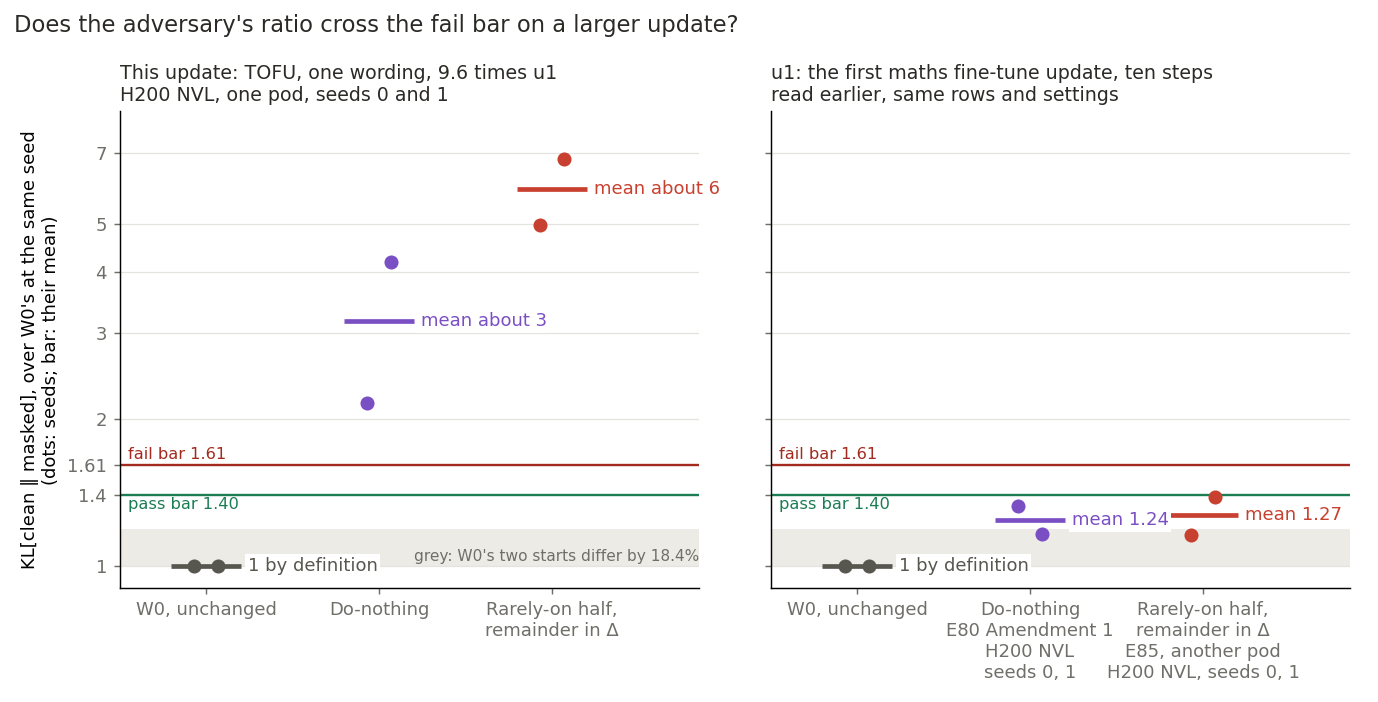

| state | ratio, seeds 0 and 1 | mean | excess in nats | on u1, mean |
|---|---|---|---|---|
| do-nothing | 2.15, 4.19 | 3.17 | 1.96, 4.59 | 1.24 |
| rarely-on half | 4.99, 6.80 | 5.90 | 6.80, 8.35 | 1.27 |

In [2]:
display(Image(FIG / "ratio_by_seed.png", width=900))
ex = S["excess"]
table(["state", "ratio, seeds 0 and 1", "mean", "excess in nats", "on u1, mean"],
      [["do-nothing", f"{S['r']['N'][0]:.2f}, {S['r']['N'][1]:.2f}", f"{S['mean']['N']:.2f}", f"{ex['N_W_s0']:.2f}, {ex['N_W_s1']:.2f}", f"{U1_N['mean']['N']:.2f}"],
       ["rarely-on half", f"{S['r']['Rare'][0]:.2f}, {S['r']['Rare'][1]:.2f}", f"{S['mean']['Rare']:.2f}", f"{ex['Rare_W_s0']:.2f}, {ex['Rare_W_s1']:.2f}", f"{U1_RARE['mean']['Rare']:.2f}"]])


**Reading it.** Yes: both states fail at both seeds, where on u1 both sat under the pass bar. Do-nothing reads about 3 against 1.24 on u1, with seeds of 2.15 and 4.19. The rarely-on half, remainder in Δ, reads about 6 against 1.27. The caveat is that size and kind are confounded. This update differs from u1 in both, and web rows relate to each differently, since u1 was maths and this one invented biographies. So the figure does not show that size caused the fail.

### Does the ratio follow the share of the update left in Δ?


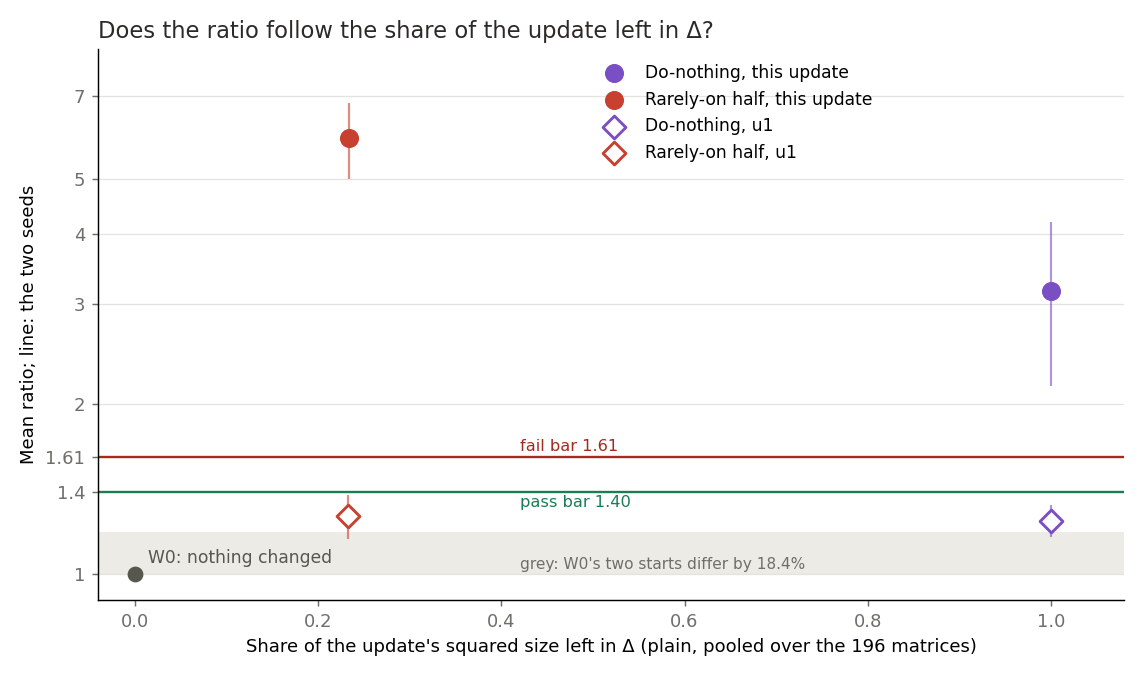

| update | state | left in Δ | mean ratio |
|---|---|---|---|
| this one | do-nothing | 1 by construction | 3.17 |
| this one | rarely-on half | 0.234 | 5.90 |
| u1 | do-nothing | 1 by construction | 1.24 |
| u1 | rarely-on half | 0.233 | 1.27 |

In [3]:
display(Image(FIG / "ratio_vs_left.png", width=800))
table(["update", "state", "left in Δ", "mean ratio"],
      [["this one", "do-nothing", "1 by construction", f"{S['mean']['N']:.2f}"],
       ["this one", "rarely-on half", f"{S['left_in_delta']['Rare']:.3f}", f"{S['mean']['Rare']:.2f}"],
       ["u1", "do-nothing", "1 by construction", f"{U1_N['mean']['N']:.2f}"],
       ["u1", "rarely-on half", f"{U1_RARE['left_in_delta']['Rare']:.3f}", f"{U1_RARE['mean']['Rare']:.2f}"]])


**Reading it.** No, as an observation and not an explanation. The rarely-on half leaves 0.234 of the update's squared size in Δ against do-nothing's 1, and it reads higher at both seeds. The half's share is almost the same on u1, while its ratio is over four times lower there. These are not the same failure. Most of the half's update sits on moved columns, which the adversary can mask out column by column, where do-nothing has one Δ setting per matrix. That route was not separately tested.

### Had the search finished, and when do the states leave W0?


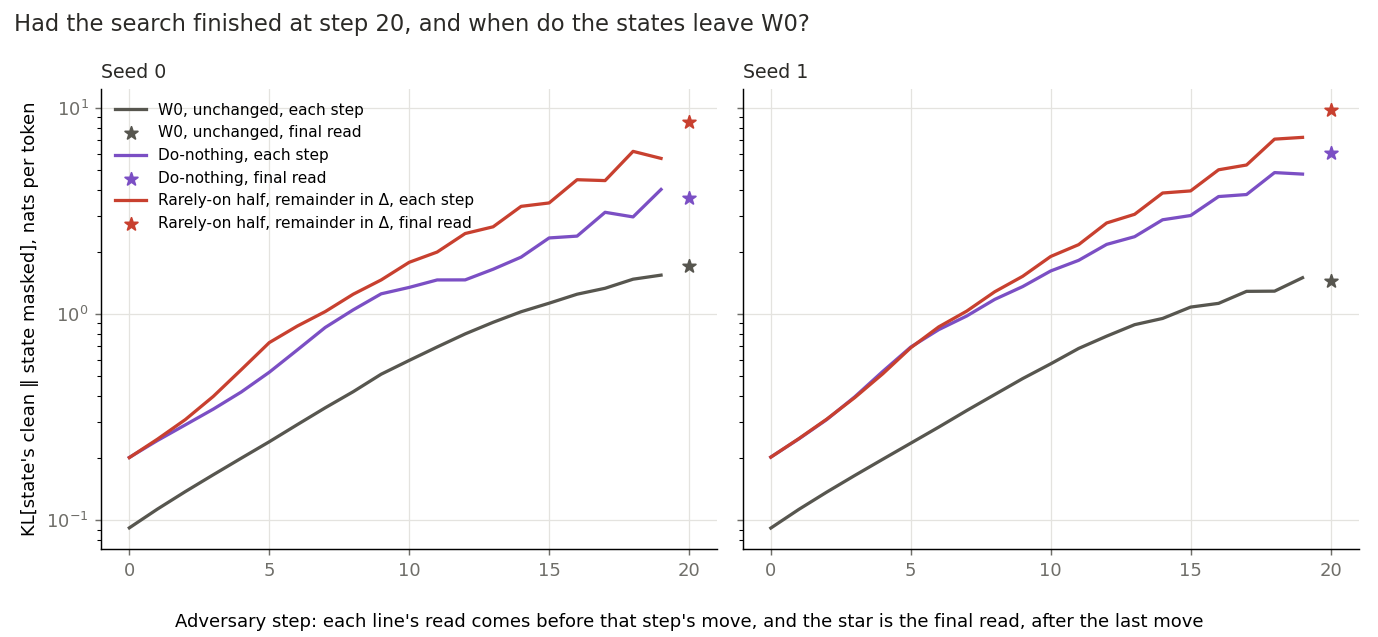

| ratio at | step 0 | step 10 | step 19 | final |
|---|---|---|---|---|
| W0, unchanged, seed 0 | 1.00 | 1.00 | 1.00 | 1.00 |
| W0, unchanged, seed 1 | 1.00 | 1.00 | 1.00 | 1.00 |
| do-nothing, seed 0 | 2.19 | 2.26 | 2.60 | 2.15 |
| do-nothing, seed 1 | 2.21 | 2.82 | 3.18 | 4.19 |
| rarely-on half, remainder in Δ, seed 0 | 2.19 | 2.99 | 3.68 | 4.99 |
| rarely-on half, remainder in Δ, seed 1 | 2.21 | 3.32 | 4.79 | 6.80 |

In [4]:
display(Image(FIG / "steps.png", width=900))
rows = []
for state in ("W0", "N", "Rare"):
    for seed in (0, 1):
        key, w0 = f"{state}_W_s{seed}", f"W0_W_s{seed}"
        t, b = trace(key), trace(w0)
        rows.append([f"{NAMES[state]}, seed {seed}", f"{t[0] / b[0]:.2f}", f"{t[10] / b[10]:.2f}", f"{t[19] / b[19]:.2f}", f"{R['starts'][key]['kl'] / R['starts'][w0]['kl']:.2f}"])
table(["ratio at", "step 0", "step 10", "step 19", "final"], rows)


**Reading it.** The search had not finished, so every read is a lower bound. Both states' KL[state's clean ‖ state masked] rises 12% to 16% per step over the last five reads, and W0's about 8%. The late reads swing, so a final ratio's size is not to be leaned on. But the fail does not rest on it: over all 20 steps the lowest single-seed ratio is 1.81 for do-nothing and 2.18 for the rarely-on half, above the bar of 1.61. Both already read about 2.2 times W0 at step 0, at random settings before any search, where on u1 they read about 1.

### What does the fail say?

**Reading it.** Not yet which of two things it is. With input $x$ at a site, the masked forward gives clean − masked $= xV(1-m)U + (1-d)x\Delta$, where $d$ is the adversary's one Δ setting per matrix. For do-nothing, $\Delta = \Delta_0 + \delta W$. So the update's own move can come back into the read by the test's design: pushing $d$ down moves that matrix toward W0. The activations and importances also come from the updated model, a second route. The final settings were not saved, so no saved number splits the two, and we claim no mechanism.

## What we learned

On this update the test fails doing nothing, with the whole update in Δ, and what that fail consists of is unread. That bears on `GOALS.md`'s weak version, in which Δ may not absorb the update. No state here is a good one, so the test has still not been shown to pass any good placement. It is not shown to separate good from bad. Nor is it shown to fail bad placements in general: wrong columns failed only at 250 to 740 times a real update's size. So D1 gets a fail here and still no pass.

## How compelling is the evidence

Strong that both states read over the bar on this update and these rows, at every seed and step. The independent check recomputed the labels and found no bug. Weak beyond that: one update, two seeds, one pod.

**Blind to.** The ratio reads web rows, not TOFU's own. It says nothing about a good placement. It separates neither size from kind nor the update switched off from harm under masks. The bars are the 67M's.

**Noise floor.** Do-nothing's two seeds differ by 2.04, a factor of 2, and the floor at this size was unmeasured. Its last-five mean is 2.70. The plan's floor at u1's size was 0.12 to 0.19. The rarely-on half on u1 already differed by 0.23, beyond it. W0's seeds differ by 18.4%.

**The update's own move.** KL[W0's clean ‖ state's clean] is 0.64 nats per token on these rows, the same for both states. On other web rows u1's reads about 16 to 18 times less, against 9.6 times in norm. So web rows do hear this update.

**Host.** One H200 NVL on a non-datacenter Vast host, as no datacenter offers existed. W0's first eight steps match earlier pods to four places. Its finals differ by 0.06% and 0.03%, so not to every digit, but far under the 18.4% between seeds. u1's 1.24 was also on an H200 NVL, which corrects the plan's "H100".

## Surprises

**Something unexpected happened that I cannot explain.** The filed scaling gave a ratio near 30 and 51 nats. Do-nothing read about 3, about ten times less. Its seed 0 excess read 1.96 nats, about 26 times less. The lean that it fails held; the reasoning behind it did not, and it should not be repeated.

- **Do-nothing's seeds** differ over ten times more than at u1's size. No cause was measured.
- **At step 0** the two states read within 0.2% of each other at both seeds, although their shares in Δ differ four times. No cause was tested.
- **The rarely-on half's share** could have passed 1 at this size. It read 0.234, against 0.233 on u1.

## What next

These are proposals; the current plan closes D1 by the clean table with no further runs on this question, and the choice sits on the user's card.

- **One do-nothing start with every Δ setting held at 1, about 22 minutes.** If the excess collapses, the fail is mostly the update switched off. If it stays, it is mostly harm under masks.
- **Least squares on this update, two starts, about $3.** A pass where these two fail means the test tells placements apart at this size. A fail means the ratio cannot score a map at this size.
- **Do-nothing on a saved TOFU state near u1's size.** A pass points to size, and a fail to kind.

## Scorecard

| id | claim in words | rule | read | verdict |
|---|---|---|---|---|
| do_nothing | do-nothing fails on this larger update | mean ≥ 1.61, gap over W0's spread | 3.17, gap 2.17, spread 0.184 | "do-nothing fails on this larger update"; medium-high lean held |
| pair | both fail | both labels fail | fails, fails | "both fail"; medium lean held |
| Rare_below_N | rarely-on half below do-nothing by more than W0's spread | difference of means over spread | −2.72 | did not happen; low lean |
| scaling | do-nothing's mean about 10 or more, near 30 | expected value, no rule | 3.17 | missed by about ten times |
| W0_s0, W0_s1 | W0 within 20% of 1.7032, 1.4379 | stop | 1.7042, 1.4389 | held |
| N_moves | KL[W0's clean ‖ do-nothing's clean] at least 1e-3 | stop | 0.6385 | held; above the expected 0.01 to 0.2 |
| Rare_left | left in Δ above least squares' 0.0984 | stop | 0.234 | held |
| Rare_same_weights | same clean KL as do-nothing within 1e-6 | stop | difference 0 | held |

## Departures from the literature

VPD runs its adversary on the model its decomposition was fitted to; here Γ is frozen on weights it was not fitted to, because that is the question. VPD reports the KL with no ratio or bar; both are this project's, the bars carried from the 67M. Components are fp32 where the authors use bf16, which cannot hold moved columns. The report has the full list.

## Departures from the plan

The code writer cut the half's active-share check and the straddle, kept and near leans. Left in Δ was rewritten without the random change. The pair rule reads "no call" where a state is unread, having no "unread" label. Two extras ran that the rule does not read: do-nothing's path check on each entry, and an older read's unused reference logits, computed with this update.

## Not run

Least squares or any map on this update, so no state on it is shown to pass. The five-wording update. TOFU's rows under the adversary. A third seed. More than 20 steps. A size ladder. KL[updated model's clean ‖ W0's clean]. The earlier controls' Δ-off read on do-nothing. One do-nothing start with every Δ setting held at 1. Which subcomponents the adversary raises. A cause for any surprise above.

**Provenance.** `experiments/qwen_tofu_adversary/results/results.json`, `run.log`, `plot.py`. u1's reads are in `experiments/qwen_d1_adversary/results/amend2.json` and `experiments/qwen_d1_teeth/results/results.json`. Pod $9.97 by the runner's report, against the plan's $10 to $14. Record: `reports/analyses/2026-11-05_analysis_e89-tofu-adversary.md`.
